In [6]:
# Run once, then restart the kernel. This covers all four notebooks.
%pip install -q pandas numpy geopandas pyogrio shapely osmnx networkx scipy scikit-learn openpyxl matplotlib gurobipy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("..")      # the data files sit one folder above notebooks/
TRAFFIC = ROOT / "Automated_Traffic_Volume_Counts_20261104.csv"

BETA = 0.15                                    # how much extra traffic slows travel

# 01 Traffic congestion factor

We slow down ambulance travel times at busy hours with a factor kappa for each of four 6-hour periods. Here we work it out from NYC DOT's automated traffic counts, Manhattan only.

In [8]:
cols = {"requestid", "boro", "yr", "m", "d", "hh", "mm", "vol", "segmentid", "direction"}
df = pd.read_csv(TRAFFIC, usecols=lambda c: c.strip().lower() in cols)    # skips the large map column
df.columns = [c.strip().lower() for c in df.columns]
print(df.shape)
print(df["boro"].value_counts())

mn = df[df["boro"].astype(str).str.strip().str.upper() == "MANHATTAN"].copy()
mn["year"] = np.where(mn["yr"] < 100, 2000 + mn["yr"], mn["yr"])          # years come as two digits
mn["date"] = pd.to_datetime(dict(year=mn["year"], month=mn["m"], day=mn["d"]), errors="coerce")
mn["slot"] = mn["hh"] * 60 + mn["mm"]                                      # minutes since midnight
mn["period"] = mn["hh"] // 6                                               # 0 = 00-06, 1 = 06-12, 2 = 12-18, 3 = 18-24
print("Manhattan rows:", len(mn), "| years:", mn["year"].min(), "to", mn["year"].max())

(1875154, 10)
boro
Queens           560928
Brooklyn         540695
Manhattan        343555
Bronx            308124
Staten Island    121852
Name: count, dtype: int64
Manhattan rows: 343555 | years: 2000 to 2026


In [9]:
# A count-day is one recorder, one street segment, one direction, one date.
key = ["requestid", "segmentid", "direction", "date"]
g = mn.groupby(key)["slot"].agg(n_rows="size", n_slots="nunique")
full_days = g.index[(g["n_rows"] == 96) & (g["n_slots"] == 96)]            # a full day has 96 fifteen-minute windows
print("count-days:", len(g), "| complete:", len(full_days), "| share:", round(len(full_days) / len(g), 3))

mn = mn.set_index(key).loc[full_days].reset_index()

count-days: 4233 | complete: 3206 | share: 0.757


Some recorders were only out for part of a day. We keep full days only. Partial days would make the later periods look quieter than they are and pull the ratios down.

volumes that could not be read: 0
           R  kappa
00-06  1.000  1.000
06-12  2.429  1.214
12-18  2.794  1.269
18-24  2.421  1.213
count-days used: 3126 | street segments: 371


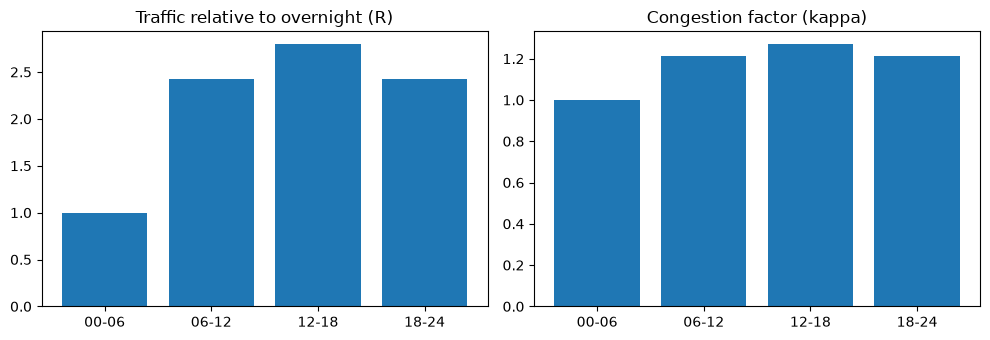

In [10]:
mn["vol"] = pd.to_numeric(mn["vol"].astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
print("volumes that could not be read:", int(mn["vol"].isna().sum()))

daily = mn.pivot_table(index=key, columns="period", values="vol", aggfunc="sum")
daily.columns = ["P1", "P2", "P3", "P4"]
daily = daily[daily["P1"] > 0]                 # drop days with no overnight traffic (a broken counter)

R = daily.mean() / daily["P1"].mean()          # how busy each period is compared with overnight
kappa = 1 + BETA * (R - 1).clip(lower=0)

result = pd.DataFrame({"R": R.values, "kappa": kappa.values},
                      index=["00-06", "06-12", "12-18", "18-24"])
print(result.round(3).to_string())
result.to_csv(ROOT / "kappa_t.csv")      # notebook 03 and the sensitivity analysis read this
print("count-days used:", len(daily), "| street segments:", daily.reset_index()["segmentid"].nunique())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for k, (col, ttl) in enumerate([("R", "Traffic relative to overnight (R)"), ("kappa", "Congestion factor (kappa)")]):
    ax[k].bar(result.index, result[col], color="#1f77b4")
    ax[k].set_title(ttl)
plt.tight_layout()
plt.show()

R is a ratio of averages: the average volume in each period divided by the average overnight volume. Averaging each day's own ratio instead gives R of 6 to 9, because quiet streets with only a handful of cars overnight blow the ratio up, so we don't use it.

Kappa adds 15% of the extra traffic to travel time, so it is 1.000 overnight and highest in the 12-18 period.